In [3]:
from pathlib import Path

dataset_path = Path("../RFMiD")

images_path = dataset_path / "1. Original Images" / "1. Original Images"
labels_path = dataset_path / "2. Groundtruths" / "2. Groundtruths"

print("IMAGE FOLDERS:")
for item in images_path.iterdir():
    print(" -", item.name)

print("\nGROUND TRUTH FILES/FOLDERS:")
for item in labels_path.iterdir():
    print(" -", item.name)

IMAGE FOLDERS:
 - a. Training Set
 - b. Validation Set
 - c. Testing Set

GROUND TRUTH FILES/FOLDERS:
 - a. RFMiD_Training_Labels.csv
 - b. RFMiD_Validation_Labels.csv
 - c. RFMiD_Testing_Labels.csv


In [4]:
import pandas as pd

train_csv = labels_path / "a. RFMiD_Training_Labels.csv"
val_csv = labels_path / "b. RFMiD_Validation_Labels.csv"
test_csv = labels_path / "c. RFMiD_Testing_Labels.csv"

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())

Training shape: (1920, 47)
Validation shape: (640, 47)
Testing shape: (640, 47)


,ID,Disease_Risk,DR,ARMD,MH,DN,MYA,BRVO,TSLN,ERM,...,CME,PTCR,CF,VH,MCA,VS,BRAO,PLQ,HPED,CL
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
disease_columns = train_df.columns.drop(["ID", "Disease_Risk"])

disease_counts = train_df[disease_columns].sum().sort_values(ascending=False)

display(disease_counts)

DR      376
MH      317
ODC     282
TSLN    186
DN      138
MYA     101
ARMD    100
BRVO     73
ODP      65
ODE      58
LS       47
RS       43
CSR      37
CRS      32
CRVO     28
RPEC     22
AION     17
AH       16
MS       15
EDN      15
ERM      14
RT       14
MHL      11
PT       11
TV        6
RP        6
ST        5
PTCR      5
CME       4
CF        3
CWS       3
MNF       3
TD        3
BRAO      2
PRH       2
CRAO      2
CB        1
VS        1
PLQ       1
MCA       1
VH        1
HPED      1
CL        1
ODPM      0
HR        0
dtype: int64

In [6]:
train_images_path = images_path / "a. Training Set"

print("Training folder contents:")
for item in list(train_images_path.iterdir())[:10]:
    print(item.name)

Training folder contents:
1.png
10.png
100.png
1000.png
1001.png
1002.png
1003.png
1004.png
1005.png
1006.png


In [7]:
selected_diseases = [
    "DR", "MH", "ODC", "TSLN",
    "DN", "MYA", "ARMD", "BRVO"
]

counts = pd.DataFrame({
    "Train": train_df[selected_diseases].sum(),
    "Validation": val_df[selected_diseases].sum(),
    "Test": test_df[selected_diseases].sum()
})

display(counts)

,Train,Validation,Test
DR,376,132,124
MH,317,102,104
ODC,282,72,91
TSLN,186,65,53
DN,138,46,46
MYA,101,34,32
ARMD,100,38,31
BRVO,73,23,23


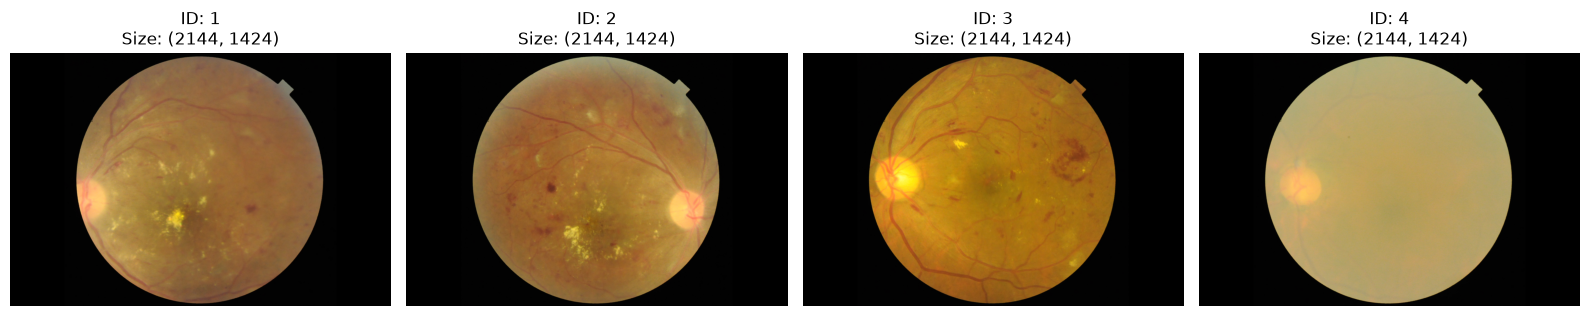

In [9]:
from PIL import Image
import matplotlib.pyplot as plt

sample_ids = train_df["ID"].head(4)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, image_id in zip(axes, sample_ids):
    image_path = train_images_path / f"{image_id}.png"
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(f"ID: {image_id}\nSize: {image.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from torchvision import transforms

# ImageNet normalization parameters
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Preprocessing pipeline
preprocess = transforms.Compose([
    transforms.Lambda(
        lambda img: ImageOps.pad(
            img,
            (224, 224),
            method=Image.Resampling.BILINEAR,
            color=(0, 0, 0)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Load a sample
image_path = train_images_path / "1.png"
original = Image.open(image_path).convert("RGB")

# Apply preprocessing
processed = preprocess(original)

print("Original image size:", original.size)
print("Processed tensor shape:", processed.shape)

Original image size: (2144, 1424)
Processed tensor shape: torch.Size([3, 224, 224])


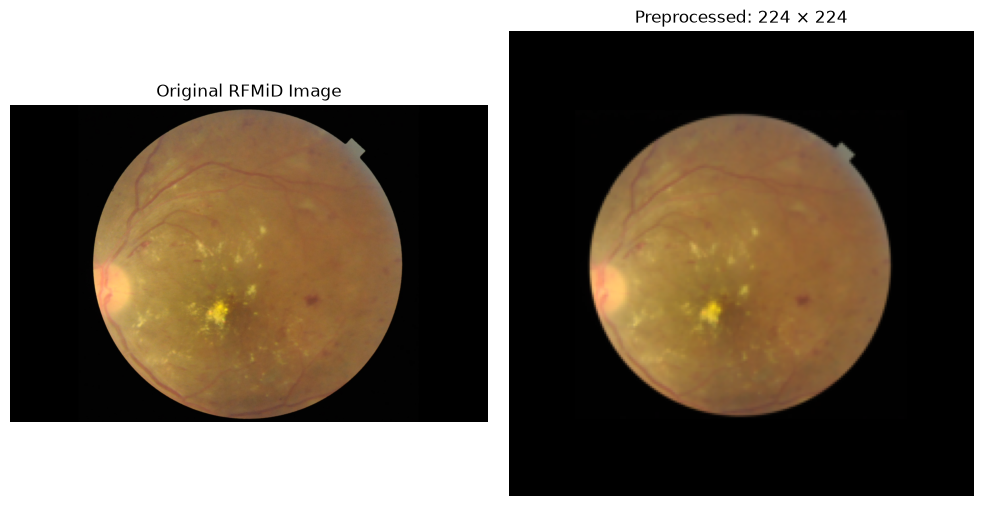

In [11]:
# Reverse normalization for visualization
display_image = processed.clone()

for channel in range(3):
    display_image[channel] = (
        display_image[channel] * std[channel] + mean[channel]
    )

display_image = display_image.clamp(0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original)
axes[0].set_title("Original RFMiD Image")
axes[0].axis("off")

axes[1].imshow(display_image.permute(1, 2, 0))
axes[1].set_title("Preprocessed: 224 × 224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

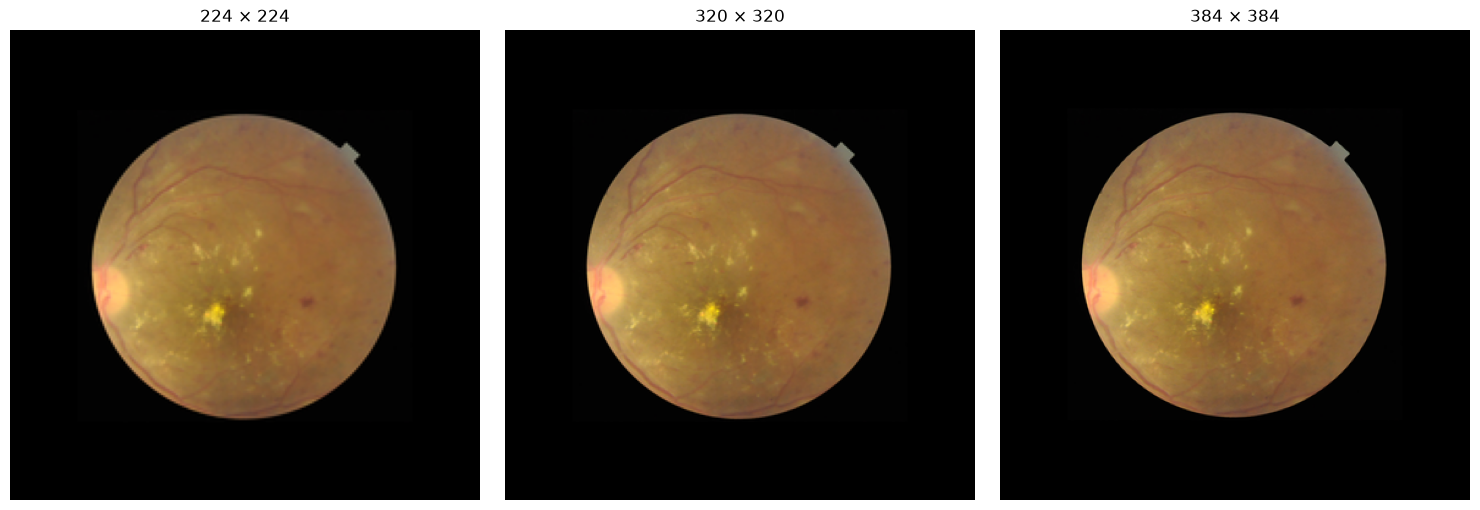

In [12]:
from PIL import ImageOps, Image
import matplotlib.pyplot as plt

sizes = [224, 320, 384]
original = Image.open(train_images_path / "1.png").convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, size in zip(axes, sizes):
    processed = ImageOps.pad(
        original,
        (size, size),
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

    ax.imshow(processed)
    ax.set_title(f"{size} × {size}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import torch
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = 320

preprocess = transforms.Compose([
    transforms.Lambda(
        lambda img: ImageOps.pad(
            img,
            (IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.LANCZOS,
            color=(0, 0, 0)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [15]:
class FundusDataset(Dataset):

    def __init__(self, dataframe, image_dir, diseases, transform):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.diseases = diseases
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / f"{row['ID']}.png"

        image = Image.open(image_path).convert("RGB")
        image = self.transform(image)

        labels = torch.tensor(
            row[self.diseases].to_numpy(dtype="float32"),
            dtype=torch.float32
        )

        return image, labels

In [16]:
val_images_path = images_path / "b. Validation Set"
test_images_path = images_path / "c. Testing Set"

train_dataset = FundusDataset(
    train_df, train_images_path, selected_diseases, preprocess
)

val_dataset = FundusDataset(
    val_df, val_images_path, selected_diseases, preprocess
)

test_dataset = FundusDataset(
    test_df, test_images_path, selected_diseases, preprocess
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1920
Validation samples: 640
Testing samples: 640


In [17]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Labels dtype:", labels.dtype)
print("First label vector:", labels[0])
print("Disease order:", selected_diseases)

Images shape: torch.Size([8, 3, 320, 320])
Labels shape: torch.Size([8, 8])
Image dtype: torch.float32
Labels dtype: torch.float32
First label vector: tensor([0., 0., 0., 0., 0., 0., 0., 0.])
Disease order: ['DR', 'MH', 'ODC', 'TSLN', 'DN', 'MYA', 'ARMD', 'BRVO']


In [18]:
import torch
from torch import nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Freeze pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# Replace the original classifier with 8 outputs
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 8)

# Move model to Intel Arc GPU
device = torch.device("xpu")
model = model.to(device)

print("Device:", device)
print("Original classifier input features:", in_features)
print("New classifier:", model.classifier)

Device: xpu
Original classifier input features: 1280
New classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=8, bias=True)
)


In [19]:
model.eval()

with torch.no_grad():
    images, labels = next(iter(train_loader))
    images = images.to(device)

    logits = model(images)

print("Input shape:", images.shape)
print("Output shape:", logits.shape)
print("Output device:", logits.device)

Input shape: torch.Size([8, 3, 320, 320])
Output shape: torch.Size([8, 8])
Output device: xpu:0


In [20]:
# Calculate positive weights from training labels only
positive_counts = train_df[selected_diseases].sum()
negative_counts = len(train_df) - positive_counts

pos_weight = torch.tensor(
    (negative_counts / positive_counts).values,
    dtype=torch.float32,
    device=device
)

# Loss function
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Optimizer: update only trainable parameters
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Positive weights:")
for disease, weight in zip(selected_diseases, pos_weight.tolist()):
    print(f"{disease}: {weight:.2f}")

Positive weights:
DR: 4.11
MH: 5.06
ODC: 5.81
TSLN: 9.32
DN: 12.91
MYA: 18.01
ARMD: 18.20
BRVO: 25.30


In [21]:
import time

model.train()
model.features.eval()  # Keep frozen backbone BatchNorm statistics fixed

start = time.time()
running_loss = 0.0

for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    logits = model(images)
    loss = criterion(logits, labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Training loss: {running_loss / len(train_loader):.4f}")
print(f"Epoch time: {time.time() - start:.1f} seconds")

Training loss: 1.0027
Epoch time: 609.4 seconds


In [22]:
from sklearn.metrics import precision_recall_fscore_support
import numpy as np

model.eval()

val_loss = 0.0
all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        val_loss += loss.item()

        probs = torch.sigmoid(logits)

        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

all_probs = np.concatenate(all_probs)
all_labels = np.concatenate(all_labels)

predictions = (all_probs >= 0.5).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    predictions,
    average=None,
    zero_division=0
)

print(f"Validation Loss: {val_loss / len(val_loader):.4f}\n")

print(f"{'Disease':<10} {'Precision':<12} {'Recall':<10} {'F1':<10}")

for i, disease in enumerate(selected_diseases):
    print(f"{disease:<10} {precision[i]:<12.3f} {recall[i]:<10.3f} {f1[i]:<10.3f}")

Validation Loss: 0.8596

Disease    Precision    Recall     F1        
DR         0.516        0.856      0.644     
MH         0.615        0.814      0.700     
ODC        0.180        0.694      0.286     
TSLN       0.388        0.800      0.523     
DN         0.128        0.674      0.215     
MYA        0.252        1.000      0.402     
ARMD       0.096        0.947      0.174     
BRVO       0.124        0.522      0.200     


In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score

print(f"{'Disease':<10} {'AUROC':<10} {'AP':<10}")

for i, disease in enumerate(selected_diseases):
    auc = roc_auc_score(all_labels[:, i], all_probs[:, i])
    ap = average_precision_score(all_labels[:, i], all_probs[:, i])

    print(f"{disease:<10} {auc:<10.3f} {ap:<10.3f}")

Disease    AUROC      AP        
DR         0.912      0.744     
MH         0.943      0.813     
ODC        0.685      0.280     
TSLN       0.887      0.407     
DN         0.718      0.170     
MYA        0.974      0.691     
ARMD       0.872      0.447     
BRVO       0.844      0.152     


In [24]:
from sklearn.metrics import precision_recall_curve, f1_score
import numpy as np

best_thresholds = []

print(f"{'Disease':<10} {'Old F1':<10} {'Threshold':<12} {'New F1':<10}")

for i, disease in enumerate(selected_diseases):
    y_true = all_labels[:, i]
    y_prob = all_probs[:, i]

    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-8)
    )

    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]

    old_f1 = f1_score(y_true, y_prob >= 0.5)
    new_f1 = f1_score(y_true, y_prob >= best_threshold)

    best_thresholds.append(best_threshold)

    print(
        f"{disease:<10} {old_f1:<10.3f} "
        f"{best_threshold:<12.3f} {new_f1:<10.3f}"
    )

Disease    Old F1     Threshold    New F1    
DR         0.644      0.676        0.701     
MH         0.700      0.688        0.742     
ODC        0.286      0.653        0.359     
TSLN       0.523      0.612        0.577     
DN         0.215      0.653        0.301     
MYA        0.402      0.870        0.600     
ARMD       0.174      0.776        0.442     
BRVO       0.200      0.618        0.255     


In [25]:
def extract_features(loader):
    features_list = []
    labels_list = []

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            features = model.features(images)
            features = model.avgpool(features)
            features = torch.flatten(features, 1)

            features_list.append(features.cpu())
            labels_list.append(labels)

    return torch.cat(features_list), torch.cat(labels_list)


train_features, train_labels = extract_features(train_loader)
val_features, val_labels = extract_features(val_loader)

print("Training features:", train_features.shape)
print("Validation features:", val_features.shape)

Training features: torch.Size([1920, 1280])
Validation features: torch.Size([640, 1280])


In [26]:
from torch.utils.data import TensorDataset, DataLoader

train_feature_loader = DataLoader(
    TensorDataset(train_features, train_labels),
    batch_size=64,
    shuffle=True
)

val_feature_loader = DataLoader(
    TensorDataset(val_features, val_labels),
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_feature_loader))
print("Validation batches:", len(val_feature_loader))

Training batches: 30
Validation batches: 10


In [27]:
import time
import copy
import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.metrics import f1_score

NUM_EPOCHS = 5

# Use the thresholds obtained after Epoch 1
thresholds = np.array(best_thresholds)

best_f1 = -1.0
best_classifier = copy.deepcopy(model.classifier.state_dict())

for epoch in range(NUM_EPOCHS):
    start = time.time()

    # ---------- TRAINING ----------
    model.classifier.train()
    train_loss = 0.0

    progress = tqdm(
        train_feature_loader,
        desc=f"Epoch {epoch + 2}/{NUM_EPOCHS + 1}"
    )

    for features, labels in progress:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model.classifier(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss /= len(train_feature_loader)

    # ---------- VALIDATION ----------
    model.classifier.eval()
    val_loss = 0.0
    probs_list = []
    labels_list = []

    with torch.no_grad():
        for features, labels in val_feature_loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model.classifier(features)
            loss = criterion(logits, labels)

            val_loss += loss.item()

            probs_list.append(torch.sigmoid(logits).cpu().numpy())
            labels_list.append(labels.cpu().numpy())

    val_loss /= len(val_feature_loader)

    probs = np.concatenate(probs_list)
    actual = np.concatenate(labels_list)

    predictions = (probs >= thresholds).astype(int)

    macro_f1 = f1_score(
        actual, predictions,
        average="macro",
        zero_division=0
    )

    label_accuracy = (predictions == actual).mean()

    torch.xpu.synchronize()
    elapsed = time.time() - start

    # ---------- SAVE BEST MODEL ----------
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_classifier = copy.deepcopy(
            model.classifier.state_dict()
        )

        torch.save({
            "classifier": best_classifier,
            "thresholds": thresholds,
            "diseases": selected_diseases,
            "macro_f1": best_f1,
            "epoch": epoch + 2
        }, "best_fundus_head.pth")

    print(
        f"Epoch {epoch + 2} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro F1: {macro_f1:.4f} | "
        f"Label Acc: {label_accuracy:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

print(f"\nBest validation Macro F1: {best_f1:.4f}")

C:\Users\spgai\anaconda3\envs\llava-xpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Epoch 2/6: 100%|██████████| 30/30 [00:01<00:00, 23.70it/s, loss=0.8329]


Epoch 2 | Train Loss: 0.8394 | Val Loss: 0.8390 | Macro F1: 0.3973 | Label Acc: 0.8908 | Time: 1.35s


Epoch 3/6: 100%|██████████| 30/30 [00:00<00:00, 71.85it/s, loss=0.8032]


Epoch 3 | Train Loss: 0.8171 | Val Loss: 0.8220 | Macro F1: 0.4192 | Label Acc: 0.8908 | Time: 0.49s


Epoch 4/6: 100%|██████████| 30/30 [00:00<00:00, 65.97it/s, loss=0.8972]


Epoch 4 | Train Loss: 0.8035 | Val Loss: 0.8134 | Macro F1: 0.4406 | Label Acc: 0.9027 | Time: 0.54s


Epoch 5/6: 100%|██████████| 30/30 [00:00<00:00, 67.69it/s, loss=0.8142]


Epoch 5 | Train Loss: 0.7897 | Val Loss: 0.8000 | Macro F1: 0.4651 | Label Acc: 0.8996 | Time: 0.54s


Epoch 6/6: 100%|██████████| 30/30 [00:00<00:00, 59.99it/s, loss=0.7278]


Epoch 6 | Train Loss: 0.7810 | Val Loss: 0.7959 | Macro F1: 0.4799 | Label Acc: 0.8902 | Time: 0.60s

Best validation Macro F1: 0.4799


In [28]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_recall_fscore_support
)
import numpy as np

# Step 1: Get updated validation predictions
model.classifier.eval()

probs_list = []
labels_list = []

with torch.no_grad():
    for features, labels in val_feature_loader:
        features = features.to(device)

        logits = model.classifier(features)
        probs = torch.sigmoid(logits)

        probs_list.append(probs.cpu().numpy())
        labels_list.append(labels.numpy())

val_probs = np.concatenate(probs_list)
val_actual = np.concatenate(labels_list)

# Step 2: Optimize thresholds for the current model
new_thresholds = []

for i in range(len(selected_diseases)):
    precision, recall, thresholds = precision_recall_curve(
        val_actual[:, i], val_probs[:, i]
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-8)
    )

    best_idx = np.argmax(f1_scores)
    new_thresholds.append(thresholds[best_idx])

new_thresholds = np.array(new_thresholds)

# Step 3: Calculate new evaluation metrics
predictions = (val_probs >= new_thresholds).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    val_actual, predictions,
    average=None,
    zero_division=0
)

print(f"{'Disease':<10} {'Threshold':<12} {'Precision':<12} {'Recall':<10} {'F1':<10}")

for i, disease in enumerate(selected_diseases):
    print(
        f"{disease:<10} "
        f"{new_thresholds[i]:<12.3f} "
        f"{precision[i]:<12.3f} "
        f"{recall[i]:<10.3f} "
        f"{f1[i]:<10.3f}"
    )

print(f"\nEpoch 6 Tuned Macro F1: {f1.mean():.4f}")

Disease    Threshold    Precision    Recall     F1        
DR         0.695        0.724        0.735      0.729     
MH         0.639        0.781        0.735      0.758     
ODC        0.638        0.369        0.431      0.397     
TSLN       0.633        0.532        0.646      0.583     
DN         0.618        0.216        0.478      0.297     
MYA        0.801        0.605        0.676      0.639     
ARMD       0.679        0.513        0.526      0.519     
BRVO       0.757        0.240        0.522      0.329     

Epoch 6 Tuned Macro F1: 0.5315


In [30]:
import time
import copy
import numpy as np
import torch
from tqdm import tqdm
from sklearn.metrics import f1_score

NUM_EPOCHS = 10

# Fixed thresholds from Epoch 1
fixed_thresholds = np.array(best_thresholds)

# Starting from the current Epoch 6 model
best_val_loss = float("inf")
best_state = copy.deepcopy(model.classifier.state_dict())

history = []

for epoch in range(8, 17):
    start = time.time()

    # ---------- TRAIN ----------
    model.classifier.train()
    running_loss = 0.0

    progress = tqdm(
        train_feature_loader,
        desc=f"Epoch {epoch}/16"
    )

    for features, labels in progress:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model.classifier(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / len(train_feature_loader)

    # ---------- VALIDATE ----------
    model.classifier.eval()

    val_loss = 0.0
    probs_list = []
    labels_list = []

    with torch.no_grad():
        for features, labels in val_feature_loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model.classifier(features)
            val_loss += criterion(logits, labels).item()

            probs_list.append(torch.sigmoid(logits).cpu().numpy())
            labels_list.append(labels.cpu().numpy())

    val_loss /= len(val_feature_loader)

    probabilities = np.concatenate(probs_list)
    actual = np.concatenate(labels_list)

    predictions = (probabilities >= fixed_thresholds).astype(int)

    macro_f1 = f1_score(
        actual,
        predictions,
        average="macro",
        zero_division=0
    )

    label_accuracy = (predictions == actual).mean()

    torch.xpu.synchronize()
    elapsed = time.time() - start

    # ---------- BEST CHECKPOINT ----------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.classifier.state_dict())

        torch.save({
            "classifier": best_state,
            "epoch": epoch,
            "val_loss": best_val_loss,
            "diseases": selected_diseases
        }, "best_fundus_head_val_loss.pth")

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro F1: {macro_f1:.4f} | "
        f"Label Acc: {label_accuracy:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

print(f"\nBest validation loss (Epochs 7–16): {best_val_loss:.4f}")

Epoch 8/16: 100%|██████████| 30/30 [00:00<00:00, 69.56it/s, loss=0.6868]


Epoch 08 | Train Loss: 0.7559 | Val Loss: 0.7730 | Macro F1: 0.4814 | Label Acc: 0.8959 | Time: 0.50s


Epoch 9/16: 100%|██████████| 30/30 [00:00<00:00, 60.56it/s, loss=0.6562]


Epoch 09 | Train Loss: 0.7499 | Val Loss: 0.7727 | Macro F1: 0.4898 | Label Acc: 0.9020 | Time: 0.57s


Epoch 10/16: 100%|██████████| 30/30 [00:00<00:00, 61.99it/s, loss=0.7271]


Epoch 10 | Train Loss: 0.7406 | Val Loss: 0.7627 | Macro F1: 0.4780 | Label Acc: 0.8971 | Time: 0.56s


... (8 outputs left out)

Epoch 15/16: 100%|██████████| 30/30 [00:00<00:00, 64.09it/s, loss=0.7724]


Epoch 15 | Train Loss: 0.6996 | Val Loss: 0.7386 | Macro F1: 0.5030 | Label Acc: 0.9062 | Time: 0.54s


Epoch 16/16: 100%|██████████| 30/30 [00:00<00:00, 76.72it/s, loss=0.7309]


Epoch 16 | Train Loss: 0.6911 | Val Loss: 0.7301 | Macro F1: 0.5127 | Label Acc: 0.9041 | Time: 0.46s

Best validation loss (Epochs 7–16): 0.7301


In [31]:
# Restore the classifier selected by validation loss
model.classifier.load_state_dict(best_state)
model.classifier.eval()

print("Best validation loss:", best_val_loss)
print("Classifier restored successfully.")

Best validation loss: 0.7301322042942047
Classifier restored successfully.


In [32]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score
)
import numpy as np
import torch

# Restore best classifier (Epoch 16)
model.classifier.load_state_dict(best_state)
model.classifier.eval()

# Get validation predictions
probs_list = []
labels_list = []

with torch.no_grad():
    for features, labels in val_feature_loader:
        logits = model.classifier(features.to(device))

        probs_list.append(torch.sigmoid(logits).cpu().numpy())
        labels_list.append(labels.numpy())

val_probs = np.concatenate(probs_list)
val_actual = np.concatenate(labels_list)

# Find F1-optimal thresholds
final_thresholds = []

for i in range(len(selected_diseases)):
    p, r, thresholds = precision_recall_curve(
        val_actual[:, i], val_probs[:, i]
    )

    f1_scores = 2 * p[:-1] * r[:-1] / (
        p[:-1] + r[:-1] + 1e-8
    )

    final_thresholds.append(thresholds[np.argmax(f1_scores)])

final_thresholds = np.array(final_thresholds)

# Evaluate predictions
predictions = (val_probs >= final_thresholds).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    val_actual, predictions, average=None, zero_division=0
)

print(
    f"{'Disease':<9} {'Threshold':<11} {'Precision':<11} "
    f"{'Recall':<9} {'F1':<9} {'AUROC':<9} {'AP':<9}"
)

for i, disease in enumerate(selected_diseases):
    auc = roc_auc_score(val_actual[:, i], val_probs[:, i])
    ap = average_precision_score(val_actual[:, i], val_probs[:, i])

    print(
        f"{disease:<9} {final_thresholds[i]:<11.3f} "
        f"{precision[i]:<11.3f} {recall[i]:<9.3f} "
        f"{f1[i]:<9.3f} {auc:<9.3f} {ap:<9.3f}"
    )

print(f"\nEpoch 16 Tuned Macro F1: {f1.mean():.4f}")

Disease   Threshold   Precision   Recall    F1        AUROC     AP       
DR        0.754       0.763       0.758     0.760     0.935     0.806    
MH        0.640       0.798       0.735     0.765     0.956     0.845    
ODC       0.611       0.393       0.458     0.423     0.740     0.348    
TSLN      0.620       0.495       0.708     0.582     0.913     0.405    
DN        0.600       0.245       0.500     0.329     0.752     0.198    
MYA       0.846       0.694       0.735     0.714     0.984     0.798    
ARMD      0.675       0.451       0.605     0.517     0.911     0.508    
BRVO      0.801       0.526       0.435     0.476     0.899     0.333    

Epoch 16 Tuned Macro F1: 0.5709


In [33]:
torch.save({
    "model_state_dict": model.state_dict(),
    "thresholds": final_thresholds,
    "diseases": selected_diseases,
    "image_size": IMG_SIZE,
    "macro_f1": 0.5709,
    "epoch": 16
}, "fundus_epoch16_baseline.pth")

print("Epoch 16 baseline saved successfully!")

Epoch 16 baseline saved successfully!


In [34]:
print("Number of feature blocks:", len(model.features))

for i, block in enumerate(model.features):
    print(i, type(block).__name__)

Number of feature blocks: 9
0 Conv2dNormActivation
1 Sequential
2 Sequential
3 Sequential
4 Sequential
5 Sequential
6 Sequential
7 Sequential
8 Conv2dNormActivation


In [35]:
# Freeze all backbone blocks
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze only blocks 7 and 8
for param in model.features[7:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# New optimizer for fine-tuning
finetune_optimizer = torch.optim.AdamW([
    {"params": model.features[7:].parameters(), "lr": 1e-5},
    {"params": model.classifier.parameters(), "lr": 1e-4}
])

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 1139640


In [36]:
import time
from tqdm.auto import tqdm

start = time.time()

model.train()

# Keep frozen blocks in evaluation mode
for block in model.features[:7]:
    block.eval()

running_loss = 0.0

for images, labels in tqdm(train_loader, desc="Fine-tuning Epoch 1"):
    images = images.to(device)
    labels = labels.to(device)

    finetune_optimizer.zero_grad()

    logits = model(images)
    loss = criterion(logits, labels)

    loss.backward()
    finetune_optimizer.step()

    running_loss += loss.item()

torch.xpu.synchronize()

print(f"Fine-tuning Loss: {running_loss / len(train_loader):.4f}")
print(f"Epoch Time: {time.time() - start:.1f} seconds")

Fine-tuning Epoch 1: 100%|██████████| 240/240 [05:12<00:00,  1.30s/it]

Fine-tuning Loss: 0.7997
Epoch Time: 312.0 seconds


In [37]:
from sklearn.metrics import f1_score

model.eval()
val_loss = 0.0
probs_list = []
labels_list = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Validating fine-tuned model"):
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        val_loss += criterion(logits, labels).item()

        probs_list.append(torch.sigmoid(logits).cpu().numpy())
        labels_list.append(labels.cpu().numpy())

val_probs_ft = np.concatenate(probs_list)
val_actual_ft = np.concatenate(labels_list)

# Use the frozen-backbone model's thresholds for initial comparison
predictions_ft = (
    val_probs_ft >= final_thresholds
).astype(int)

print(f"Fine-tuned Validation Loss: {val_loss / len(val_loader):.4f}")
print(f"Fine-tuned Macro F1: {f1_score(val_actual_ft, predictions_ft, average='macro', zero_division=0):.4f}")

Validating fine-tuned model: 100%|██████████| 80/80 [01:46<00:00,  1.33s/it]

Fine-tuned Validation Loss: 0.7491
Fine-tuned Macro F1: 0.5218


In [38]:
from sklearn.metrics import roc_auc_score, average_precision_score

print(f"{'Disease':<10} {'AUROC':<10} {'AP':<10}")

for i, disease in enumerate(selected_diseases):
    auc = roc_auc_score(val_actual_ft[:, i], val_probs_ft[:, i])
    ap = average_precision_score(val_actual_ft[:, i], val_probs_ft[:, i])

    print(f"{disease:<10} {auc:<10.3f} {ap:<10.3f}")

Disease    AUROC      AP        
DR         0.934      0.821     
MH         0.948      0.820     
ODC        0.735      0.326     
TSLN       0.897      0.390     
DN         0.759      0.196     
MYA        0.983      0.765     
ARMD       0.902      0.471     
BRVO       0.911      0.311     


In [40]:
checkpoint = torch.load(
    "fundus_epoch16_baseline.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
final_thresholds = np.array(checkpoint["thresholds"])

model.eval()

print("Restored Epoch:", checkpoint["epoch"])
print("Baseline Macro F1:", checkpoint["macro_f1"])
print("Thresholds:", final_thresholds)

Restored Epoch: 16
Baseline Macro F1: 0.5709
Thresholds: [0.7536579  0.63967824 0.61054736 0.62026256 0.5997739  0.8459525
 0.6753721  0.8009819 ]


In [41]:
from sklearn.metrics import (
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score
)
from tqdm import tqdm
import numpy as np

model.eval()
test_probs = []
test_actual = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Final Test"):
        logits = model(images.to(device))

        test_probs.append(torch.sigmoid(logits).cpu().numpy())
        test_actual.append(labels.numpy())

test_probs = np.concatenate(test_probs)
test_actual = np.concatenate(test_actual)

# Use validation-selected thresholds, without changing them
test_pred = (test_probs >= final_thresholds).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    test_actual, test_pred,
    average=None,
    zero_division=0
)

print(f"{'Disease':<9} {'Precision':<11} {'Recall':<9} {'F1':<9} {'AUROC':<9} {'AP':<9}")

for i, disease in enumerate(selected_diseases):
    auc = roc_auc_score(test_actual[:, i], test_probs[:, i])
    ap = average_precision_score(test_actual[:, i], test_probs[:, i])

    print(
        f"{disease:<9} {precision[i]:<11.3f} "
        f"{recall[i]:<9.3f} {f1[i]:<9.3f} "
        f"{auc:<9.3f} {ap:<9.3f}"
    )

print(f"\nFinal Test Macro F1: {f1.mean():.4f}")

Final Test: 100%|██████████| 80/80 [03:49<00:00,  2.87s/it]

Disease   Precision   Recall    F1        AUROC     AP       
DR        0.758       0.556     0.642     0.924     0.773    
MH        0.726       0.817     0.769     0.961     0.867    
ODC       0.371       0.363     0.367     0.735     0.403    
TSLN      0.438       0.792     0.564     0.915     0.351    
DN        0.267       0.348     0.302     0.760     0.247    
MYA       0.730       0.844     0.783     0.989     0.862    
ARMD      0.342       0.419     0.377     0.881     0.414    
BRVO      0.400       0.435     0.417     0.901     0.300    

Final Test Macro F1: 0.5274


In [42]:
from sklearn.metrics import confusion_matrix

for disease in ["DR", "ARMD"]:
    i = selected_diseases.index(disease)
    threshold = final_thresholds[i]

    print(f"\n{disease} | Threshold: {threshold:.3f}")

    for split, actual, probs in [
        ("Validation", val_actual, val_probs),
        ("Test", test_actual, test_probs)
    ]:
        pred = (probs[:, i] >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            actual[:, i], pred, labels=[0, 1]
        ).ravel()

        print(
            f"{split:<12} "
            f"TP={tp:<4} FP={fp:<4} "
            f"FN={fn:<4} TN={tn:<4}"
        )


DR | Threshold: 0.754
Validation   TP=100  FP=31   FN=32   TN=477 
Test         TP=69   FP=22   FN=55   TN=494 

ARMD | Threshold: 0.675
Validation   TP=23   FP=28   FN=15   TN=574 
Test         TP=13   FP=25   FN=18   TN=584 


In [44]:
from torchvision.models import resnet50, ResNet50_Weights

resnet_model = resnet50(weights=ResNet50_Weights.DEFAULT)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\spgai/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [01:07<00:00, 1.52MB/s]


In [45]:
from torchvision.models import resnet50, ResNet50_Weights
from torch import nn
import torch

# Freeze pretrained backbone
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace ImageNet classifier with our 8-disease classifier
in_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(in_features, len(selected_diseases))

# Move model to Intel Arc GPU
resnet_model = resnet_model.to(device)

print("Device:", device)
print("Classifier input features:", in_features)
print("New classifier:", resnet_model.fc)
print("Trainable parameters:",
      sum(p.numel() for p in resnet_model.parameters() if p.requires_grad))

Device: xpu
Classifier input features: 2048
New classifier: Linear(in_features=2048, out_features=8, bias=True)
Trainable parameters: 16392


In [46]:
from torch import nn
from tqdm.auto import tqdm

# Everything except the final classification layer
resnet_backbone = nn.Sequential(
    *list(resnet_model.children())[:-1]
)

resnet_backbone.eval()

def extract_resnet_features(loader, description):
    features_list = []
    labels_list = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc=description):
            images = images.to(device)

            features = resnet_backbone(images)
            features = torch.flatten(features, 1)

            features_list.append(features.cpu())
            labels_list.append(labels)

    return torch.cat(features_list), torch.cat(labels_list)

resnet_train_features, resnet_train_labels = extract_resnet_features(
    train_loader, "ResNet training features"
)

resnet_val_features, resnet_val_labels = extract_resnet_features(
    val_loader, "ResNet validation features"
)

print("Training features:", resnet_train_features.shape)
print("Validation features:", resnet_val_features.shape)

ResNet validation features: 100%|██████████| 80/80 [03:23<00:00,  2.54s/it]

Training features: torch.Size([1920, 2048])
Validation features: torch.Size([640, 2048])


In [47]:
from torch.utils.data import TensorDataset, DataLoader

# Create DataLoaders using cached ResNet features
resnet_train_loader = DataLoader(
    TensorDataset(resnet_train_features, resnet_train_labels),
    batch_size=64,
    shuffle=True
)

resnet_val_loader = DataLoader(
    TensorDataset(resnet_val_features, resnet_val_labels),
    batch_size=64,
    shuffle=False
)

# Separate optimizer for ResNet's classifier
resnet_optimizer = torch.optim.AdamW(
    resnet_model.fc.parameters(),
    lr=0.001
)

print("Training batches:", len(resnet_train_loader))
print("Validation batches:", len(resnet_val_loader))

Training batches: 30
Validation batches: 10


In [48]:
import time
import copy
import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.metrics import f1_score

NUM_EPOCHS = 10

best_val_loss = float("inf")
best_resnet_state = None
resnet_history = []

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.time()

    # ---------- TRAIN ----------
    resnet_model.fc.train()
    running_loss = 0.0

    progress = tqdm(
        resnet_train_loader,
        desc=f"ResNet Epoch {epoch}/{NUM_EPOCHS}"
    )

    for features, labels in progress:
        features = features.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        logits = resnet_model.fc(features)
        loss = criterion(logits, labels)

        loss.backward()
        resnet_optimizer.step()

        running_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / len(resnet_train_loader)

    # ---------- VALIDATION ----------
    resnet_model.fc.eval()

    val_loss = 0.0
    probs_list = []
    labels_list = []

    with torch.no_grad():
        for features, labels in resnet_val_loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = resnet_model.fc(features)
            val_loss += criterion(logits, labels).item()

            probs_list.append(torch.sigmoid(logits).cpu().numpy())
            labels_list.append(labels.cpu().numpy())

    val_loss /= len(resnet_val_loader)

    probs = np.concatenate(probs_list)
    actual = np.concatenate(labels_list)

    predictions = (probs >= 0.5).astype(int)

    macro_f1 = f1_score(
        actual,
        predictions,
        average="macro",
        zero_division=0
    )

    label_accuracy = (predictions == actual).mean()

    torch.xpu.synchronize()
    elapsed = time.time() - start

    # ---------- SAVE BEST MODEL ----------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_resnet_state = copy.deepcopy(
            resnet_model.fc.state_dict()
        )

        torch.save({
            "classifier": best_resnet_state,
            "epoch": epoch,
            "val_loss": best_val_loss,
            "diseases": selected_diseases
        }, "best_resnet50_head.pth")

    resnet_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro F1: {macro_f1:.4f} | "
        f"Label Acc: {label_accuracy:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

print(f"\nBest ResNet-50 Validation Loss: {best_val_loss:.4f}")

ResNet Epoch 1/10: 100%|██████████| 30/30 [00:00<00:00, 36.09it/s, loss=0.9748]


Epoch 01 | Train Loss: 1.1737 | Val Loss: 1.0919 | Macro F1: 0.3374 | Label Acc: 0.7008 | Time: 0.92s


ResNet Epoch 2/10: 100%|██████████| 30/30 [00:00<00:00, 86.48it/s, loss=0.9106]


Epoch 02 | Train Loss: 1.0445 | Val Loss: 1.0048 | Macro F1: 0.3689 | Label Acc: 0.7215 | Time: 0.41s


ResNet Epoch 3/10: 100%|██████████| 30/30 [00:00<00:00, 85.35it/s, loss=1.0545]


Epoch 03 | Train Loss: 0.9733 | Val Loss: 0.9540 | Macro F1: 0.3822 | Label Acc: 0.7525 | Time: 0.42s


... (10 outputs left out)

ResNet Epoch 9/10: 100%|██████████| 30/30 [00:00<00:00, 87.75it/s, loss=0.8506]


Epoch 09 | Train Loss: 0.8035 | Val Loss: 0.8351 | Macro F1: 0.4342 | Label Acc: 0.8045 | Time: 0.40s


ResNet Epoch 10/10: 100%|██████████| 30/30 [00:00<00:00, 82.75it/s, loss=0.7756]


Epoch 10 | Train Loss: 0.7898 | Val Loss: 0.8232 | Macro F1: 0.4381 | Label Acc: 0.8262 | Time: 0.43s

Best ResNet-50 Validation Loss: 0.8232


In [49]:
# Continue from the current Epoch 10 model
best_val_loss_2 = best_val_loss

for epoch in range(11, 26):
    start = time.time()

    resnet_model.fc.train()
    running_loss = 0.0

    for features, labels in resnet_train_loader:
        features = features.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        logits = resnet_model.fc(features)
        loss = criterion(logits, labels)

        loss.backward()
        resnet_optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(resnet_train_loader)

    # Validation
    resnet_model.fc.eval()
    val_loss = 0.0
    probs_list, labels_list = [], []

    with torch.no_grad():
        for features, labels in resnet_val_loader:
            logits = resnet_model.fc(features.to(device))
            labels_gpu = labels.to(device)

            val_loss += criterion(logits, labels_gpu).item()

            probs_list.append(torch.sigmoid(logits).cpu().numpy())
            labels_list.append(labels.numpy())

    val_loss /= len(resnet_val_loader)

    probs = np.concatenate(probs_list)
    actual = np.concatenate(labels_list)
    predictions = (probs >= 0.5).astype(int)

    macro_f1 = f1_score(
        actual, predictions, average="macro", zero_division=0
    )

    torch.xpu.synchronize()
    elapsed = time.time() - start

    if val_loss < best_val_loss_2:
        best_val_loss_2 = val_loss
        torch.save({
            "classifier": resnet_model.fc.state_dict(),
            "epoch": epoch,
            "val_loss": val_loss,
            "diseases": selected_diseases
        }, "best_resnet50_head_extended.pth")

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro F1: {macro_f1:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

print(f"\nBest validation loss: {best_val_loss_2:.4f}")

Epoch 11 | Train Loss: 0.7760 | Val Loss: 0.8136 | Macro F1: 0.4362 | Time: 0.38s
Epoch 12 | Train Loss: 0.7616 | Val Loss: 0.8066 | Macro F1: 0.4376 | Time: 0.40s
Epoch 13 | Train Loss: 0.7493 | Val Loss: 0.7988 | Macro F1: 0.4353 | Time: 0.39s
Epoch 14 | Train Loss: 0.7369 | Val Loss: 0.7885 | Macro F1: 0.4418 | Time: 0.35s
Epoch 15 | Train Loss: 0.7263 | Val Loss: 0.7870 | Macro F1: 0.4493 | Time: 0.35s
Epoch 16 | Train Loss: 0.7148 | Val Loss: 0.7812 | Macro F1: 0.4466 | Time: 0.39s
Epoch 17 | Train Loss: 0.7085 | Val Loss: 0.7777 | Macro F1: 0.4562 | Time: 0.37s
Epoch 18 | Train Loss: 0.6997 | Val Loss: 0.7710 | Macro F1: 0.4480 | Time: 0.34s
Epoch 19 | Train Loss: 0.6911 | Val Loss: 0.7750 | Macro F1: 0.4639 | Time: 0.37s
Epoch 20 | Train Loss: 0.6840 | Val Loss: 0.7619 | Macro F1: 0.4610 | Time: 0.34s
Epoch 21 | Train Loss: 0.6764 | Val Loss: 0.7667 | Macro F1: 0.4640 | Time: 0.33s
Epoch 22 | Train Loss: 0.6684 | Val Loss: 0.7619 | Macro F1: 0.4698 | Time: 0.39s
Epoch 23 | Train

In [50]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score
)
import numpy as np

# Restore the selected classifier
checkpoint = torch.load(
    "best_resnet50_head_extended.pth",
    map_location=device,
    weights_only=True
)

resnet_model.fc.load_state_dict(checkpoint["classifier"])
resnet_model.fc.eval()

# Generate validation scores
resnet_val_probs = []
resnet_val_actual = []

with torch.no_grad():
    for features, labels in resnet_val_loader:
        logits = resnet_model.fc(features.to(device))

        resnet_val_probs.append(torch.sigmoid(logits).cpu().numpy())
        resnet_val_actual.append(labels.numpy())

resnet_val_probs = np.concatenate(resnet_val_probs)
resnet_val_actual = np.concatenate(resnet_val_actual)

# Find per-disease thresholds
resnet_thresholds = []

for i in range(len(selected_diseases)):
    p, r, thresholds = precision_recall_curve(
        resnet_val_actual[:, i],
        resnet_val_probs[:, i]
    )

    scores = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-8)
    resnet_thresholds.append(thresholds[np.argmax(scores)])

resnet_thresholds = np.array(resnet_thresholds)

predictions = (resnet_val_probs >= resnet_thresholds).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    resnet_val_actual,
    predictions,
    average=None,
    zero_division=0
)

print(f"{'Disease':<9} {'Threshold':<11} {'Precision':<11} {'Recall':<9} {'F1':<9} {'AUROC':<9} {'AP':<9}")

for i, disease in enumerate(selected_diseases):
    auc = roc_auc_score(resnet_val_actual[:, i], resnet_val_probs[:, i])
    ap = average_precision_score(resnet_val_actual[:, i], resnet_val_probs[:, i])

    print(
        f"{disease:<9} {resnet_thresholds[i]:<11.3f} "
        f"{precision[i]:<11.3f} {recall[i]:<9.3f} "
        f"{f1[i]:<9.3f} {auc:<9.3f} {ap:<9.3f}"
    )

print(f"\nResNet Tuned Validation Macro F1: {f1.mean():.4f}")
print("Selected checkpoint epoch:", checkpoint["epoch"])

Disease   Threshold   Precision   Recall    F1        AUROC     AP       
DR        0.673       0.698       0.735     0.716     0.920     0.780    
MH        0.641       0.752       0.775     0.763     0.961     0.837    
ODC       0.499       0.277       0.542     0.366     0.723     0.320    
TSLN      0.534       0.463       0.769     0.578     0.911     0.412    
DN        0.672       0.293       0.261     0.276     0.690     0.165    
MYA       0.781       0.627       0.941     0.753     0.986     0.776    
ARMD      0.670       0.439       0.658     0.526     0.898     0.496    
BRVO      0.795       0.429       0.261     0.324     0.881     0.248    

ResNet Tuned Validation Macro F1: 0.5379
Selected checkpoint epoch: 25


In [51]:
import time
import torch
import numpy as np
from sklearn.metrics import f1_score

best_loss = best_val_loss_2
patience = 5
no_improvement = 0

for epoch in range(26, 41):
    start = time.time()
    resnet_model.fc.train()
    train_loss = 0.0

    for features, labels in resnet_train_loader:
        features = features.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        logits = resnet_model.fc(features)
        loss = criterion(logits, labels)

        loss.backward()
        resnet_optimizer.step()

        train_loss += loss.item()

    train_loss /= len(resnet_train_loader)

    # Validation
    resnet_model.fc.eval()
    val_loss = 0.0
    probs_list, labels_list = [], []

    with torch.no_grad():
        for features, labels in resnet_val_loader:
            logits = resnet_model.fc(features.to(device))
            labels = labels.to(device)

            val_loss += criterion(logits, labels).item()

            probs_list.append(torch.sigmoid(logits).cpu().numpy())
            labels_list.append(labels.cpu().numpy())

    val_loss /= len(resnet_val_loader)

    probs = np.concatenate(probs_list)
    actual = np.concatenate(labels_list)
    predictions = (probs >= 0.5).astype(int)

    macro_f1 = f1_score(
        actual, predictions,
        average="macro",
        zero_division=0
    )

    torch.xpu.synchronize()
    elapsed = time.time() - start

    if val_loss < best_loss - 0.0001:
        best_loss = val_loss
        no_improvement = 0

        torch.save({
            "classifier": resnet_model.fc.state_dict(),
            "epoch": epoch,
            "val_loss": best_loss,
            "diseases": selected_diseases
        }, "best_resnet50_head_extended.pth")
    else:
        no_improvement += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro F1: {macro_f1:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

    if no_improvement >= patience:
        print(f"\nEarly stopping at Epoch {epoch}")
        break

print(f"\nBest Validation Loss: {best_loss:.4f}")

Epoch 26 | Train Loss: 0.6424 | Val Loss: 0.7518 | Macro F1: 0.4713 | Time: 0.38s
Epoch 27 | Train Loss: 0.6361 | Val Loss: 0.7444 | Macro F1: 0.4688 | Time: 0.37s
Epoch 28 | Train Loss: 0.6315 | Val Loss: 0.7449 | Macro F1: 0.4747 | Time: 0.34s
Epoch 29 | Train Loss: 0.6243 | Val Loss: 0.7435 | Macro F1: 0.4790 | Time: 0.34s
Epoch 30 | Train Loss: 0.6181 | Val Loss: 0.7426 | Macro F1: 0.4801 | Time: 0.37s
Epoch 31 | Train Loss: 0.6134 | Val Loss: 0.7406 | Macro F1: 0.4873 | Time: 0.33s
Epoch 32 | Train Loss: 0.6082 | Val Loss: 0.7450 | Macro F1: 0.4867 | Time: 0.34s
Epoch 33 | Train Loss: 0.6048 | Val Loss: 0.7352 | Macro F1: 0.4721 | Time: 0.35s
Epoch 34 | Train Loss: 0.5995 | Val Loss: 0.7440 | Macro F1: 0.4882 | Time: 0.33s
Epoch 35 | Train Loss: 0.5939 | Val Loss: 0.7293 | Macro F1: 0.4763 | Time: 0.38s
Epoch 36 | Train Loss: 0.5906 | Val Loss: 0.7326 | Macro F1: 0.4744 | Time: 0.37s
Epoch 37 | Train Loss: 0.5852 | Val Loss: 0.7393 | Macro F1: 0.4875 | Time: 0.38s
Epoch 38 | Train

In [52]:
best_loss = 0.7289
patience = 5
no_improvement = 0

for epoch in range(41, 51):
    start = time.time()

    # Training
    resnet_model.fc.train()
    train_loss = 0.0

    for features, labels in resnet_train_loader:
        features = features.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        logits = resnet_model.fc(features)
        loss = criterion(logits, labels)

        loss.backward()
        resnet_optimizer.step()

        train_loss += loss.item()

    train_loss /= len(resnet_train_loader)

    # Validation
    resnet_model.fc.eval()
    val_loss = 0.0
    probs_list, labels_list = [], []

    with torch.no_grad():
        for features, labels in resnet_val_loader:
            logits = resnet_model.fc(features.to(device))
            labels_gpu = labels.to(device)

            val_loss += criterion(logits, labels_gpu).item()

            probs_list.append(torch.sigmoid(logits).cpu().numpy())
            labels_list.append(labels.numpy())

    val_loss /= len(resnet_val_loader)

    probs = np.concatenate(probs_list)
    actual = np.concatenate(labels_list)
    predictions = (probs >= 0.5).astype(int)

    macro_f1 = f1_score(
        actual, predictions,
        average="macro",
        zero_division=0
    )

    torch.xpu.synchronize()
    elapsed = time.time() - start

    # Save only when validation improves
    if val_loss < best_loss - 0.0001:
        best_loss = val_loss
        no_improvement = 0

        torch.save({
            "classifier": resnet_model.fc.state_dict(),
            "epoch": epoch,
            "val_loss": best_loss,
            "diseases": selected_diseases
        }, "best_resnet50_head_extended.pth")
    else:
        no_improvement += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro F1: {macro_f1:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

    if no_improvement >= patience:
        print(f"Early stopping at Epoch {epoch}")
        break

print(f"\nBest Validation Loss: {best_loss:.4f}")

Epoch 41 | Train Loss: 0.5689 | Val Loss: 0.7338 | Macro F1: 0.4941 | Time: 0.36s
Epoch 42 | Train Loss: 0.5653 | Val Loss: 0.7233 | Macro F1: 0.4797 | Time: 0.42s
Epoch 43 | Train Loss: 0.5607 | Val Loss: 0.7281 | Macro F1: 0.4890 | Time: 0.36s
Epoch 44 | Train Loss: 0.5565 | Val Loss: 0.7335 | Macro F1: 0.4886 | Time: 0.36s
Epoch 45 | Train Loss: 0.5544 | Val Loss: 0.7248 | Macro F1: 0.4882 | Time: 0.34s
Epoch 46 | Train Loss: 0.5494 | Val Loss: 0.7329 | Macro F1: 0.4954 | Time: 0.37s
Epoch 47 | Train Loss: 0.5461 | Val Loss: 0.7313 | Macro F1: 0.5013 | Time: 0.36s
Early stopping at Epoch 47

Best Validation Loss: 0.7233


In [53]:
checkpoint = torch.load(
    "best_resnet50_head_extended.pth",
    map_location=device,
    weights_only=True
)

resnet_model.fc.load_state_dict(checkpoint["classifier"])
resnet_model.eval()

print("Best ResNet epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

Best ResNet epoch: 42
Best validation loss: 0.7233435273170471


In [54]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score
)
import numpy as np

# 1. Get ResNet Epoch 42 validation predictions
resnet_model.eval()

resnet_val_probs = []
resnet_val_actual = []

with torch.no_grad():
    for features, labels in resnet_val_loader:
        logits = resnet_model.fc(features.to(device))

        resnet_val_probs.append(
            torch.sigmoid(logits).cpu().numpy()
        )
        resnet_val_actual.append(labels.numpy())

resnet_val_probs = np.concatenate(resnet_val_probs)
resnet_val_actual = np.concatenate(resnet_val_actual)

# 2. Confirm both models use aligned validation labels
assert np.array_equal(val_actual, resnet_val_actual), \
    "Validation label order mismatch!"

# 3. Average the two models' scores
ensemble_probs = (val_probs + resnet_val_probs) / 2

# 4. Find disease-specific ensemble thresholds
ensemble_thresholds = []

for i in range(len(selected_diseases)):
    p, r, thresholds = precision_recall_curve(
        val_actual[:, i], ensemble_probs[:, i]
    )

    f1_scores = 2 * p[:-1] * r[:-1] / (
        p[:-1] + r[:-1] + 1e-8
    )

    ensemble_thresholds.append(
        thresholds[np.argmax(f1_scores)]
    )

ensemble_thresholds = np.array(ensemble_thresholds)

# 5. Evaluate
predictions = (ensemble_probs >= ensemble_thresholds).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    val_actual, predictions, average=None, zero_division=0
)

print(f"{'Disease':<9} {'Threshold':<11} {'F1':<9} {'AUROC':<9} {'AP':<9}")

for i, disease in enumerate(selected_diseases):
    auc = roc_auc_score(val_actual[:, i], ensemble_probs[:, i])
    ap = average_precision_score(val_actual[:, i], ensemble_probs[:, i])

    print(
        f"{disease:<9} {ensemble_thresholds[i]:<11.3f} "
        f"{f1[i]:<9.3f} {auc:<9.3f} {ap:<9.3f}"
    )

print(f"\nEnsemble Validation Macro F1: {f1.mean():.4f}")

Disease   Threshold   F1        AUROC     AP       
DR        0.764       0.758     0.937     0.818    
MH        0.593       0.766     0.966     0.868    
ODC       0.565       0.411     0.750     0.349    
TSLN      0.532       0.599     0.926     0.436    
DN        0.604       0.303     0.733     0.189    
MYA       0.848       0.743     0.988     0.822    
ARMD      0.684       0.581     0.922     0.596    
BRVO      0.786       0.462     0.909     0.375    

Ensemble Validation Macro F1: 0.5778


In [55]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_recall_fscore_support
)
import numpy as np

resnet_thresholds = []

for i in range(len(selected_diseases)):
    p, r, thresholds = precision_recall_curve(
        resnet_val_actual[:, i],
        resnet_val_probs[:, i]
    )

    f1_scores = (
        2 * p[:-1] * r[:-1] /
        (p[:-1] + r[:-1] + 1e-8)
    )

    resnet_thresholds.append(
        thresholds[np.argmax(f1_scores)]
    )

resnet_thresholds = np.array(resnet_thresholds)

# Apply optimized thresholds
resnet_predictions = (
    resnet_val_probs >= resnet_thresholds
).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    resnet_val_actual,
    resnet_predictions,
    average=None,
    zero_division=0
)

print(f"{'Disease':<10} {'Threshold':<12} {'Precision':<12} {'Recall':<10} {'F1':<10}")

for i, disease in enumerate(selected_diseases):
    print(
        f"{disease:<10} "
        f"{resnet_thresholds[i]:<12.3f} "
        f"{precision[i]:<12.3f} "
        f"{recall[i]:<10.3f} "
        f"{f1[i]:<10.3f}"
    )

print(f"\nResNet Epoch 42 Tuned Macro F1: {f1.mean():.4f}")

Disease    Threshold    Precision    Recall     F1        
DR         0.680        0.712        0.750      0.731     
MH         0.643        0.802        0.755      0.778     
ODC        0.563        0.303        0.514      0.381     
TSLN       0.575        0.511        0.723      0.599     
DN         0.656        0.211        0.413      0.279     
MYA        0.820        0.682        0.882      0.769     
ARMD       0.701        0.474        0.711      0.568     
BRVO       0.761        0.409        0.391      0.400     

ResNet Epoch 42 Tuned Macro F1: 0.5632


In [56]:
import numpy as np
import torch
from sklearn.metrics import (
    precision_recall_curve,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# 1. Restore EfficientNet Epoch 16
eff_checkpoint = torch.load(
    "fundus_epoch16_baseline.pth",
    map_location=device,
    weights_only=False   # Our own trusted checkpoint contains NumPy thresholds
)

model.load_state_dict(eff_checkpoint["model_state_dict"])
model.eval()

# 2. Restore ResNet Epoch 42
res_checkpoint = torch.load(
    "best_resnet50_head_extended.pth",
    map_location=device,
    weights_only=True
)

resnet_model.fc.load_state_dict(res_checkpoint["classifier"])
resnet_model.eval()

# 3. Generate predictions from the SAME validation batches
eff_scores, res_scores, labels_all = [], [], []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Verifying ensemble"):
        images = images.to(device)

        eff_logits = model(images)
        res_logits = resnet_model(images)

        eff_scores.append(torch.sigmoid(eff_logits).cpu().numpy())
        res_scores.append(torch.sigmoid(res_logits).cpu().numpy())
        labels_all.append(labels.numpy())

eff_scores = np.concatenate(eff_scores)
res_scores = np.concatenate(res_scores)
labels_all = np.concatenate(labels_all)

print("EfficientNet:", eff_scores.shape)
print("ResNet:", res_scores.shape)
print("Labels:", labels_all.shape)

assert np.array_equal(labels_all, val_df[selected_diseases].to_numpy()), \
    "Validation label order mismatch!"

print("Checkpoints and validation alignment verified.")

Verifying ensemble: 100%|██████████| 80/80 [03:29<00:00,  2.61s/it]

EfficientNet: (640, 8)
ResNet: (640, 8)
Labels: (640, 8)
Checkpoints and validation alignment verified.


In [57]:
def evaluate_ensemble(eff_weight):
    scores = eff_weight * eff_scores + (1 - eff_weight) * res_scores

    thresholds = []

    for i in range(len(selected_diseases)):
        p, r, t = precision_recall_curve(labels_all[:, i], scores[:, i])

        f1_values = 2 * p[:-1] * r[:-1] / (
            p[:-1] + r[:-1] + 1e-8
        )

        thresholds.append(t[np.argmax(f1_values)])

    thresholds = np.array(thresholds)
    predictions = (scores >= thresholds).astype(int)

    macro_f1 = f1_score(
        labels_all, predictions,
        average="macro",
        zero_division=0
    )

    mean_auc = np.mean([
        roc_auc_score(labels_all[:, i], scores[:, i])
        for i in range(len(selected_diseases))
    ])

    mean_ap = np.mean([
        average_precision_score(labels_all[:, i], scores[:, i])
        for i in range(len(selected_diseases))
    ])

    return macro_f1, mean_auc, mean_ap, thresholds


for weight in [1.0, 0.0, 0.5, 0.7]:
    f1, auc, ap, thresholds = evaluate_ensemble(weight)

    print(
        f"EfficientNet weight: {weight:.1f} | "
        f"Macro F1: {f1:.4f} | "
        f"Mean AUROC: {auc:.4f} | "
        f"Mean AP: {ap:.4f}"
    )

EfficientNet weight: 1.0 | Macro F1: 0.5709 | Mean AUROC: 0.8863 | Mean AP: 0.5302
EfficientNet weight: 0.0 | Macro F1: 0.5632 | Mean AUROC: 0.8780 | Mean AP: 0.5335
EfficientNet weight: 0.5 | Macro F1: 0.5778 | Mean AUROC: 0.8915 | Mean AP: 0.5566
EfficientNet weight: 0.7 | Macro F1: 0.5789 | Mean AUROC: 0.8922 | Mean AP: 0.5511


In [58]:
torch.save({
    "efficientnet_state": model.state_dict(),
    "resnet_state": resnet_model.state_dict(),
    "thresholds": ensemble_thresholds.tolist(),
    "diseases": selected_diseases,
    "image_size": IMG_SIZE,
    "efficientnet_weight": 0.5,
    "resnet_weight": 0.5
}, "netradrishti_fundus_ensemble.pth")

print("Fundus ensemble saved successfully!")

Fundus ensemble saved successfully!


In [59]:
checkpoint = torch.load(
    "netradrishti_fundus_ensemble.pth",
    map_location="cpu",
    weights_only=True
)

print("Models saved:",
      list(checkpoint.keys()))

print("Disease labels:",
      checkpoint["diseases"])

print("Thresholds:",
      checkpoint["thresholds"])

print("Ensemble weights:",
      checkpoint["efficientnet_weight"],
      checkpoint["resnet_weight"])

Models saved: ['efficientnet_state', 'resnet_state', 'thresholds', 'diseases', 'image_size', 'efficientnet_weight', 'resnet_weight']
Disease labels: ['DR', 'MH', 'ODC', 'TSLN', 'DN', 'MYA', 'ARMD', 'BRVO']
Thresholds: [0.7639826536178589, 0.5925266146659851, 0.5654981136322021, 0.5317577719688416, 0.6042940616607666, 0.8475929498672485, 0.6836636662483215, 0.78584885597229]
Ensemble weights: 0.5 0.5


In [60]:
from torchvision.models import efficientnet_b0, resnet50
from torch import nn

# Create fresh model architectures
eff_loaded = efficientnet_b0(weights=None)
eff_loaded.classifier[1] = nn.Linear(1280, 8)

res_loaded = resnet50(weights=None)
res_loaded.fc = nn.Linear(2048, 8)

# Load saved trained weights
eff_loaded.load_state_dict(checkpoint["efficientnet_state"])
res_loaded.load_state_dict(checkpoint["resnet_state"])

eff_loaded = eff_loaded.to(device).eval()
res_loaded = res_loaded.to(device).eval()

# Take one validation image
image, _ = val_dataset[0]
image = image.unsqueeze(0).to(device)

with torch.no_grad():
    eff_prob = torch.sigmoid(eff_loaded(image))
    res_prob = torch.sigmoid(res_loaded(image))

    ensemble_prob = (
        checkpoint["efficientnet_weight"] * eff_prob +
        checkpoint["resnet_weight"] * res_prob
    )

thresholds = torch.tensor(
    checkpoint["thresholds"],
    device=device
)

predictions = ensemble_prob[0] >= thresholds

print("Ensemble output shape:", ensemble_prob.shape)

for disease, score, predicted in zip(
    checkpoint["diseases"],
    ensemble_prob[0].cpu().tolist(),
    predictions.cpu().tolist()
):
    print(f"{disease:<6} Score: {score:.3f} | Predicted: {predicted}")

Ensemble output shape: torch.Size([1, 8])
DR     Score: 0.304 | Predicted: False
MH     Score: 0.430 | Predicted: False
ODC    Score: 0.477 | Predicted: False
TSLN   Score: 0.870 | Predicted: True
DN     Score: 0.274 | Predicted: False
MYA    Score: 0.759 | Predicted: False
ARMD   Score: 0.666 | Predicted: False
BRVO   Score: 0.309 | Predicted: False


In [61]:
print("Actual labels:", val_dataset[0][1].tolist())

Actual labels: [1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0]


In [62]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

ensemble_scores = 0.5 * eff_scores + 0.5 * res_scores
ensemble_pred = (ensemble_scores >= ensemble_thresholds).astype(int)

results = []

for i, disease in enumerate(selected_diseases):
    tn, fp, fn, tp = confusion_matrix(
        labels_all[:, i],
        ensemble_pred[:, i],
        labels=[0, 1]
    ).ravel()

    results.append({
        "Disease": disease,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Miss Rate": round(fn / (tp + fn), 3) if tp + fn else 0
    })

error_df = pd.DataFrame(results)
display(error_df)

,Disease,TP,FP,FN,TN,Miss Rate
0,DR,93,22,39,486,0.295
1,MH,77,22,25,516,0.245
2,ODC,38,75,34,493,0.472
3,TSLN,50,52,15,523,0.231
4,DN,22,83,24,511,0.522
5,MYA,25,10,9,596,0.265
6,ARMD,24,23,14,579,0.368
7,BRVO,9,7,14,610,0.609


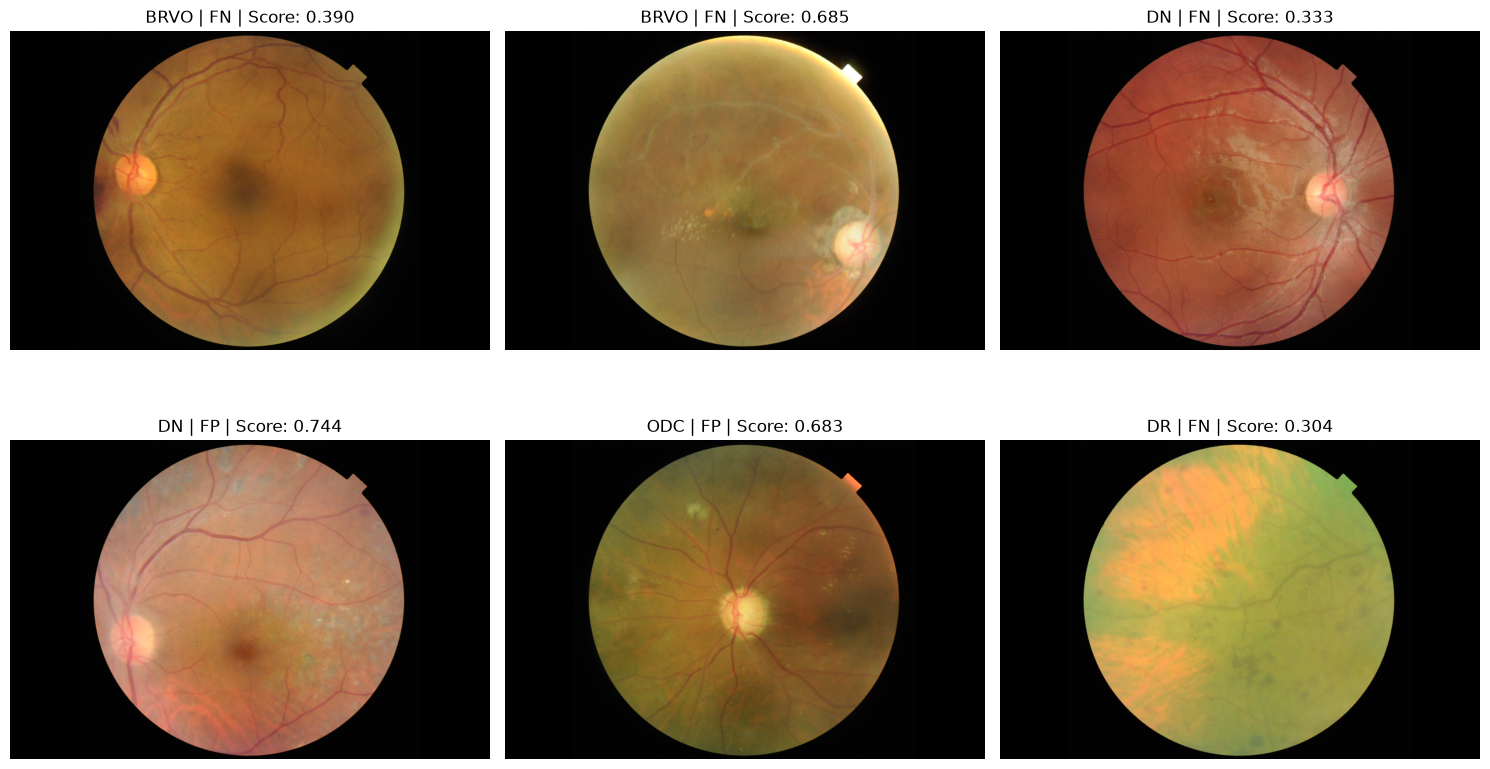

In [63]:
import matplotlib.pyplot as plt
from PIL import Image

cases = [
    ("BRVO", "FN", 2),
    ("DN", "FN", 1),
    ("DN", "FP", 1),
    ("ODC", "FP", 1),
    ("DR", "FN", 1)
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

plot_idx = 0

for disease, error_type, count in cases:
    i = selected_diseases.index(disease)

    if error_type == "FN":
        indices = np.where(
            (labels_all[:, i] == 1) &
            (ensemble_pred[:, i] == 0)
        )[0]
    else:
        indices = np.where(
            (labels_all[:, i] == 0) &
            (ensemble_pred[:, i] == 1)
        )[0]

    for idx in indices[:count]:
        image_id = val_df.iloc[idx]["ID"]
        image = Image.open(
            val_images_path / f"{image_id}.png"
        ).convert("RGB")

        axes[plot_idx].imshow(image)
        axes[plot_idx].set_title(
            f"{disease} | {error_type} | Score: "
            f"{ensemble_scores[idx, i]:.3f}"
        )
        axes[plot_idx].axis("off")
        plot_idx += 1

for ax in axes[plot_idx:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [64]:
dr_idx = selected_diseases.index("DR")

dr_fn_indices = np.where(
    (labels_all[:, dr_idx] == 1) &
    (ensemble_pred[:, dr_idx] == 0)
)[0]

image_idx = int(dr_fn_indices[0])

print("Selected validation image index:", image_idx)
print("DR ground truth:", labels_all[image_idx, dr_idx])
print("Ensemble DR score:", ensemble_scores[image_idx, dr_idx])

Selected validation image index: 0
DR ground truth: 1.0
Ensemble DR score: 0.30362964


In [65]:
target_layer = eff_loaded.features[-1]
print(target_layer)

Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


In [66]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

eff_loaded.eval()

activations = {}
gradients = {}

def save_activation(module, inputs, output):
    activations["value"] = output.detach()

def save_gradient(module, grad_input, grad_output):
    gradients["value"] = grad_output[0].detach()

forward_hook = target_layer.register_forward_hook(save_activation)
backward_hook = target_layer.register_full_backward_hook(save_gradient)

try:
    image_tensor, _ = val_dataset[image_idx]
    image_tensor = image_tensor.unsqueeze(0).to(device)

    eff_loaded.zero_grad(set_to_none=True)

    with torch.enable_grad():
        logits = eff_loaded(image_tensor)
        logits[0, dr_idx].backward()

    feature_maps = activations["value"]
    grads = gradients["value"]

    weights = grads.mean(dim=(2, 3), keepdim=True)

    cam = (weights * feature_maps).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    forward_hook.remove()
    backward_hook.remove()

print("Grad-CAM shape:", cam.shape)

Grad-CAM shape: (320, 320)


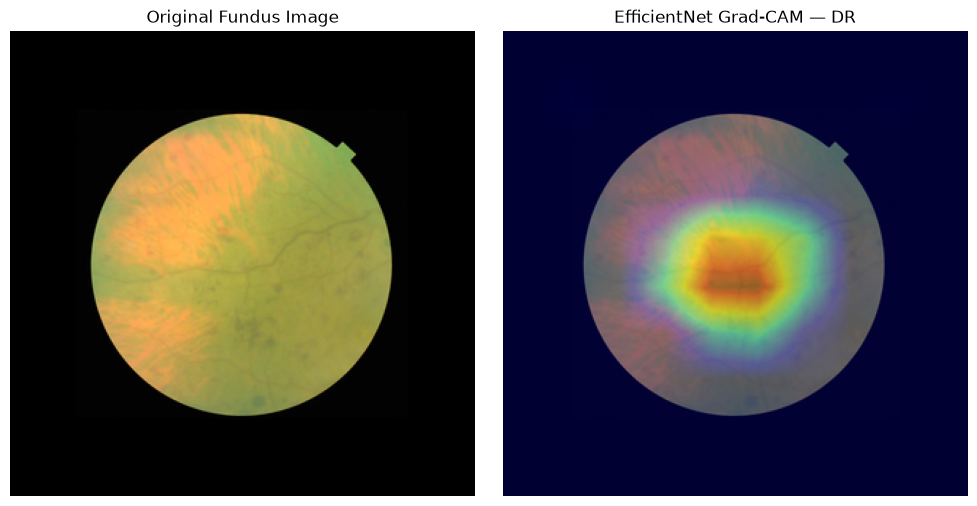

In [67]:
image = Image.open(
    val_images_path / f"{val_df.iloc[image_idx]['ID']}.png"
).convert("RGB")

display_image = ImageOps.pad(
    image,
    (IMG_SIZE, IMG_SIZE),
    method=Image.Resampling.LANCZOS,
    color=(0, 0, 0)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(display_image)
axes[0].set_title("Original Fundus Image")

axes[1].imshow(display_image)
axes[1].imshow(cam, cmap="jet", alpha=0.4)
axes[1].set_title("EfficientNet Grad-CAM — DR")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [68]:
print("Actual DR:", labels_all[image_idx, dr_idx])
print("EfficientNet DR:", round(float(eff_scores[image_idx, dr_idx]), 3))
print("ResNet DR:", round(float(res_scores[image_idx, dr_idx]), 3))
print("Ensemble DR:", round(float(ensemble_scores[image_idx, dr_idx]), 3))
print("DR threshold:", round(float(ensemble_thresholds[dr_idx]), 3))

Actual DR: 1.0
EfficientNet DR: 0.346
ResNet DR: 0.261
Ensemble DR: 0.304
DR threshold: 0.764


In [69]:
dr_tp_indices = np.where(
    (labels_all[:, dr_idx] == 1) &
    (ensemble_pred[:, dr_idx] == 1)
)[0]

tp_idx = int(dr_tp_indices[0])

print("True-positive image index:", tp_idx)
print("EfficientNet DR score:", round(float(eff_scores[tp_idx, dr_idx]), 3))
print("ResNet DR score:", round(float(res_scores[tp_idx, dr_idx]), 3))
print("Ensemble DR score:", round(float(ensemble_scores[tp_idx, dr_idx]), 3))

True-positive image index: 10
EfficientNet DR score: 0.905
ResNet DR score: 0.976
Ensemble DR score: 0.941


In [70]:
# Preserve the previous false-negative heatmap
fn_cam = cam.copy()

# Reuse our Grad-CAM hooks for the true-positive image
activations = {}
gradients = {}

forward_hook = target_layer.register_forward_hook(save_activation)
backward_hook = target_layer.register_full_backward_hook(save_gradient)

try:
    tp_tensor, _ = val_dataset[tp_idx]
    tp_tensor = tp_tensor.unsqueeze(0).to(device)

    eff_loaded.zero_grad(set_to_none=True)

    with torch.enable_grad():
        logits = eff_loaded(tp_tensor)
        logits[0, dr_idx].backward()

    feature_maps = activations["value"]
    grads = gradients["value"]

    weights = grads.mean(dim=(2, 3), keepdim=True)
    tp_cam = F.relu(
        (weights * feature_maps).sum(dim=1, keepdim=True)
    )

    tp_cam = F.interpolate(
        tp_cam,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )

    tp_cam = tp_cam[0, 0].cpu().numpy()
    tp_cam = (tp_cam - tp_cam.min()) / (
        tp_cam.max() - tp_cam.min() + 1e-8
    )

finally:
    forward_hook.remove()
    backward_hook.remove()

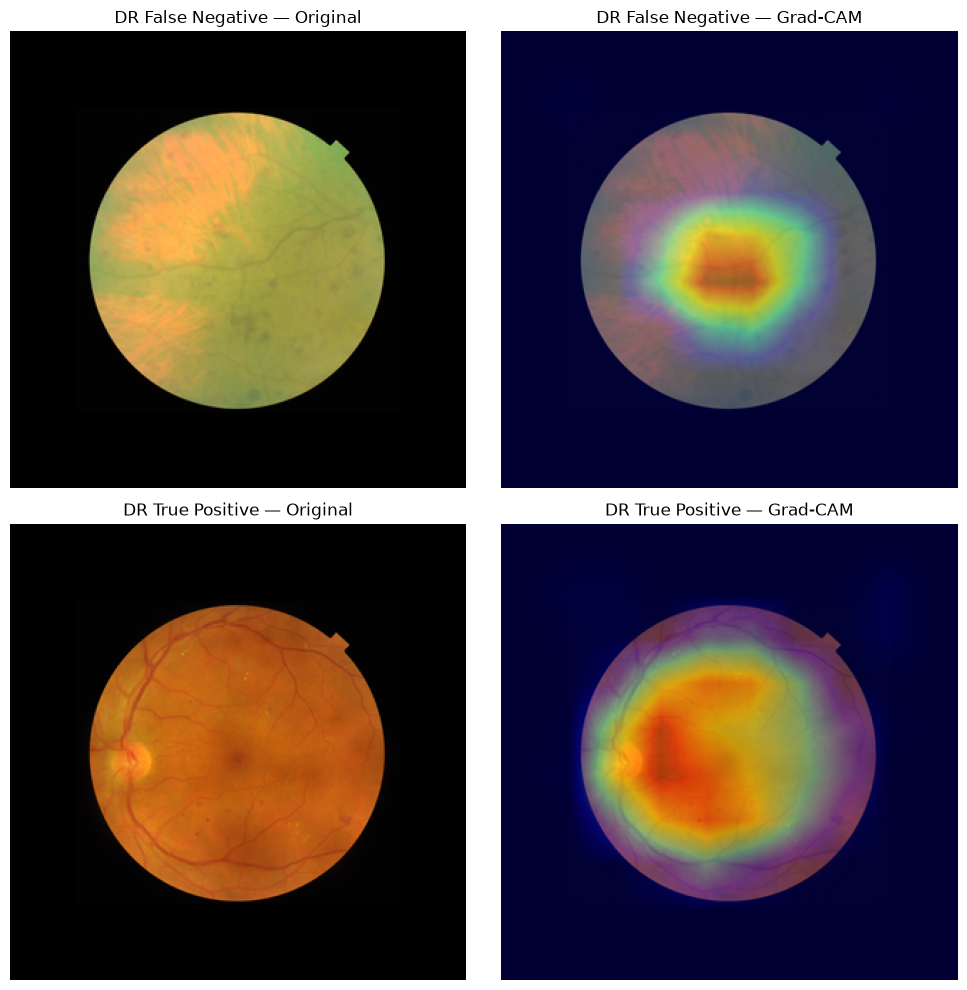

In [71]:
def show_fundus(idx):
    image_id = val_df.iloc[idx]["ID"]
    image = Image.open(
        val_images_path / f"{image_id}.png"
    ).convert("RGB")

    return ImageOps.pad(
        image,
        (IMG_SIZE, IMG_SIZE),
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for row, (idx, heatmap, label) in enumerate([
    (image_idx, fn_cam, "False Negative"),
    (tp_idx, tp_cam, "True Positive")
]):
    original = show_fundus(idx)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"DR {label} — Original")

    axes[row, 1].imshow(original)
    axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.4)
    axes[row, 1].set_title(f"DR {label} — Grad-CAM")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [74]:
from pathlib import Path
import sys

print("Current directory:", Path.cwd())
print("Project folder exists:", (Path.cwd().parent / "inference" / "predictor.py").is_file())

Current directory: C:\Users\spgai\OneDrive\Documents\NetraDrishti\notebooks
Project folder exists: False


In [75]:
from pathlib import Path
import sys

project_path = Path.home() / "OneDrive" / "Documents" / "NetraDrishti"

sys.path.insert(0, str(project_path))

from inference.predictor import NetraDrishtiPredictor

print("Predictor imported successfully!")

ModuleNotFoundError: No module named 'inference.predictor'

In [77]:
from pathlib import Path

locations = [
    Path.home() / "Documents" / "NetraDrishti",
    Path.home() / "OneDrive" / "Documents" / "NetraDrishti"
]

for folder in locations:
    file = folder / "inference" / "predictor.py"
    print(file, "->", file.exists())

C:\Users\spgai\Documents\NetraDrishti\inference\predictor.py -> False
C:\Users\spgai\OneDrive\Documents\NetraDrishti\inference\predictor.py -> False


In [79]:
from pathlib import Path

file_path = Path(r"C:\Users\spgai\OneDrive\Documents\NetraDrishti\inference\predictor.py.py")

print("File exists:", file_path.is_file())
print("Actual location:", file_path.parent)

File exists: True
Actual location: C:\Users\spgai\OneDrive\Documents\NetraDrishti\inference


In [81]:
import sys

sys.path.insert(0, str(file_path.parent.parent))

from inference.predictor import NetraDrishtiPredictor

print("Predictor imported successfully!")

Predictor imported successfully!


In [82]:
predictor = NetraDrishtiPredictor()

image_path = val_images_path / f"{val_df.iloc[0]['ID']}.png"

with Image.open(image_path) as img:
    result = predictor.predict_fundus(img)

for disease, prediction in result.items():
    print(disease, prediction)

DR {'score': 0.3036, 'threshold': 0.764, 'detected': False}
MH {'score': 0.4303, 'threshold': 0.5925, 'detected': False}
ODC {'score': 0.4767, 'threshold': 0.5655, 'detected': False}
TSLN {'score': 0.8696, 'threshold': 0.5318, 'detected': True}
DN {'score': 0.2742, 'threshold': 0.6043, 'detected': False}
MYA {'score': 0.7591, 'threshold': 0.8476, 'detected': False}
ARMD {'score': 0.6658, 'threshold': 0.6837, 'detected': False}
BRVO {'score': 0.3095, 'threshold': 0.7858, 'detected': False}


In [83]:
print("OCT model checkpoint files:")
for path in Path(".").rglob("*.pth"):
    print(path)

OCT model checkpoint files:
best_fundus_head.pth
best_fundus_head_val_loss.pth
best_resnet50_head.pth
best_resnet50_head_extended.pth
fundus_epoch16_baseline.pth
netradrishti_fundus_ensemble.pth


In [84]:
from pathlib import Path
import torch

oct_path = Path("../models/swin_tiny_epoch3.pth")

oct_checkpoint = torch.load(
    oct_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(oct_checkpoint))

if isinstance(oct_checkpoint, dict):
    print("First 15 keys:", list(oct_checkpoint.keys())[:15])

Checkpoint type: <class 'dict'>
First 15 keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'class_to_idx']


In [85]:
print("Saved epoch:", oct_checkpoint["epoch"])
print("Class mapping:", oct_checkpoint["class_to_idx"])

state = oct_checkpoint["model_state_dict"]

print("\nClassification head:")
for key, value in state.items():
    if "head" in key:
        print(key, tuple(value.shape))

Saved epoch: 3
Class mapping: {'CNV': 0, 'DME': 1, 'DRUSEN': 2, 'NORMAL': 3}

Classification head:
head.weight (4, 768)
head.bias (4,)
